# 1. Definición del problema: CREDIT_LIMIT

**Objetivo:** predecir `CREDIT_LIMIT` a partir del comportamiento de uso de 8,950 tarjetas de crédito.

**Métricas:** MAE (error típico), RMSE (penaliza errores grandes) y R².

**Alcance:** modelo descriptivo/exploratorio; no se infiere causalidad. La moneda del dataset no está documentada.

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [76]:
from sklearn import set_config
set_config (transform_output="pandas")
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, KFold, train_test_split, cross_val_score, cross_validate
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import KNNImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.compose import ColumnTransformer,TransformedTargetRegressor
from sklearn.metrics import r2_score, root_mean_squared_error,mean_absolute_error,make_scorer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.base import clone
from scipy.stats import wilcoxon
from sklearn.inspection import permutation_importance
from pathlib import Path #Dataset

2. Recolección de datos

In [77]:
NOMBRE = "CC GENERAL.csv"
candidatas = [Path(NOMBRE), Path("data") / NOMBRE, Path.home() / "Downloads" / NOMBRE]
path = next((p for p in candidatas if p.exists()), None)

if path is None:  # respaldo: descarga desde Kaggle (pip install kagglehub)
    try:
        import kagglehub
        path = Path(kagglehub.dataset_download("arjunbhasin2013/ccdata")) / NOMBRE
    except Exception as e:
        raise FileNotFoundError(f"No se encontró '{NOMBRE}'. Colócalo en data/ o junto al notebook. Detalle: {e}")

print("Usando:", path)
data = pd.read_csv(path, sep=",", header=0, index_col="CUST_ID")
data.head()

Usando: C:\Users\kevin\Downloads\CC GENERAL.csv


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
CUST_ID,,,,,,,,,,,,,,,,,
C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


3. Comprensión de los datos (EDA)

"Se asume por contexto del dataset que CREDIT_LIMIT es función del comportamiento crediticio observado. El objetivo es modelar esa relación, no inferir causalidad."

In [78]:
data.info()
data.shape

<class 'pandas.DataFrame'>
Index: 8950 entries, C10001 to C19190
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   BALANCE                           8950 non-null   float64
 1   BALANCE_FREQUENCY                 8950 non-null   float64
 2   PURCHASES                         8950 non-null   float64
 3   ONEOFF_PURCHASES                  8950 non-null   float64
 4   INSTALLMENTS_PURCHASES            8950 non-null   float64
 5   CASH_ADVANCE                      8950 non-null   float64
 6   PURCHASES_FREQUENCY               8950 non-null   float64
 7   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 8   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 9   CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 10  CASH_ADVANCE_TRX                  8950 non-null   int64  
 11  PURCHASES_TRX                     8950 non-null   int64  
 12  CREDIT_LIMIT   

(8950, 17)

In [79]:
data.corr(numeric_only=True)["CREDIT_LIMIT"].sort_values(ascending=False).drop("CREDIT_LIMIT")

BALANCE                             0.531283
PAYMENTS                            0.421861
PURCHASES                           0.356963
ONEOFF_PURCHASES                    0.319724
CASH_ADVANCE                        0.303985
ONEOFF_PURCHASES_FREQUENCY          0.295038
PURCHASES_TRX                       0.272882
INSTALLMENTS_PURCHASES              0.256499
CASH_ADVANCE_TRX                    0.149700
TENURE                              0.139167
CASH_ADVANCE_FREQUENCY              0.132616
MINIMUM_PAYMENTS                    0.126671
PURCHASES_FREQUENCY                 0.119788
BALANCE_FREQUENCY                   0.095843
PURCHASES_INSTALLMENTS_FREQUENCY    0.060755
PRC_FULL_PAYMENT                    0.055672
Name: CREDIT_LIMIT, dtype: float64

Text(0.5, 1.0, 'Heatmap Credit Card Dataset')

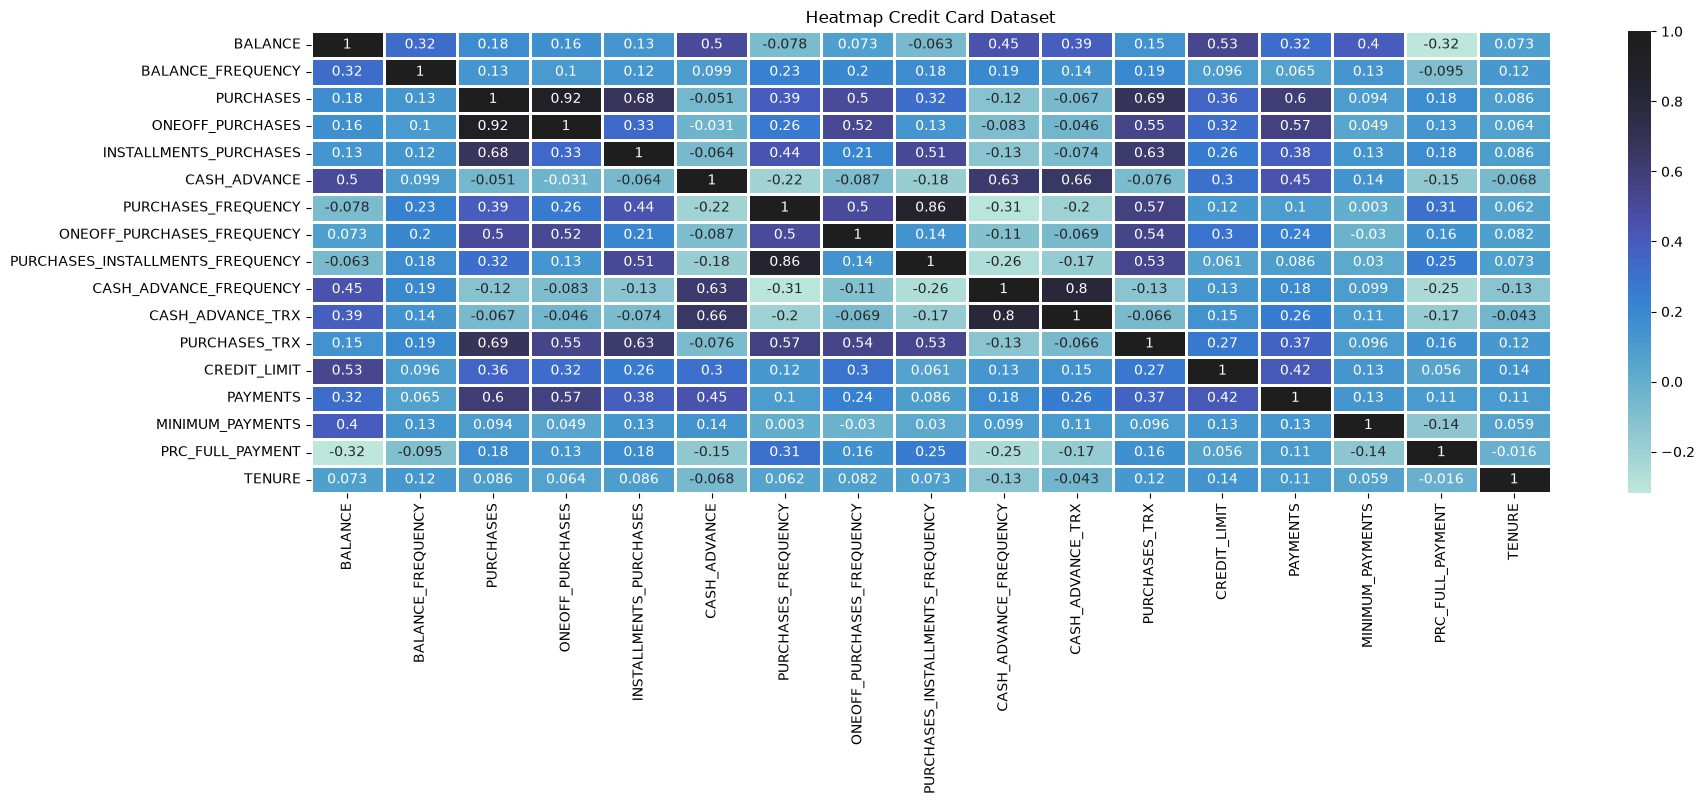

In [80]:
#Se grafica de acuerdo a la correlacion con Y sin consioderar srt's
plt.figure(figsize=(20,6))
ax=sns.heatmap(data=(data.corr()),
               center= True,
               annot=True,
               linewidths=1,
               cmap= "icefire",
               fmt= ".2g"                          
)
ax.set_title("Heatmap Credit Card Dataset")

4. Preparación de datos

In [81]:
data.columns

Index(['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
       'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
       'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX',
       'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT',
       'TENURE'],
      dtype='str')

In [82]:
# identificando nan
data_nan = data.isna().sum().sort_values(ascending=False).to_frame(name="Nan_values")
data_nan["Zeros_values"] = (data==0).sum()
data_nan

,Nan_values,Zeros_values
MINIMUM_PAYMENTS,313,0
CREDIT_LIMIT,1,0
BALANCE,0,80
BALANCE_FREQUENCY,0,80
PURCHASES,0,2044
CASH_ADVANCE,0,4628
PURCHASES_FREQUENCY,0,2043
ONEOFF_PURCHASES,0,4302
INSTALLMENTS_PURCHASES,0,3916
PURCHASES_INSTALLMENTS_FREQUENCY,0,3915


In [83]:
print(f"De acuerdo con lo validado, la columna de Zeros_values corresponde a ceros reales de acuerdo al contexto del dataset,",
      f"\npero considerando la columna de Nan_values {data_nan["Nan_values"].idxmax()} con {max(data_nan["Nan_values"])} es candidato a imputación con la KNNImputer,",
      f"\nconsiderando que el segundo elemento es {data_nan["Nan_values"].sort_values(ascending=False).index[1]} el target y solo contiene {data_nan.loc["CREDIT_LIMIT", "Nan_values"]} elemento, se optara por la eliminacion de la fila")

De acuerdo con lo validado, la columna de Zeros_values corresponde a ceros reales de acuerdo al contexto del dataset, 
pero considerando la columna de Nan_values MINIMUM_PAYMENTS con 313 es candidato a imputación con la KNNImputer, 
considerando que el segundo elemento es CREDIT_LIMIT el target y solo contiene 1 elemento, se optara por la eliminacion de la fila


In [84]:
#Elimninacion de nan si es igual o menor que 1
cols_1nan = data_nan.index[data_nan["Nan_values"]<=1].tolist()
data = data.dropna(subset=cols_1nan)

In [85]:
#segmentacion de datos
target = "CREDIT_LIMIT"
y=data[target]
X= data.drop(columns=target)
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state= 42,train_size=.8)

In [86]:
#Escalar para imputar
inv_scaler = StandardScaler()
X_train_inv = inv_scaler.fit_transform(X_train)
X_test_inv = inv_scaler.transform(X_test)

In [87]:
#Identificar Nan en X
X_nan = X.isna().sum().sort_values(ascending=False).to_frame(name="Nan_values_x")
cols_nan_X = X_nan[X_nan["Nan_values_x"] > 0].index.tolist()
print(f"Columnas a imputar {cols_nan_X}")

Columnas a imputar ['MINIMUM_PAYMENTS']


In [88]:
#Definiendo instancia del imputer
imputer = KNNImputer(n_neighbors=5)

#Reemplazar Nan en X
X_train_inv = imputer.fit_transform(X_train_inv)
X_test_inv = imputer.transform(X_test_inv)
print(f"Columnas imputadas: {cols_nan_X}")

Columnas imputadas: ['MINIMUM_PAYMENTS']


In [89]:
#Revertir escalado
X_train = pd.DataFrame(inv_scaler.inverse_transform(X_train_inv),
                       columns=X_train_inv.columns, 
                       index=X_train_inv.index)
X_test = pd.DataFrame(inv_scaler.inverse_transform(X_test_inv),
                      columns=X_test_inv.columns, 
                      index= X_test_inv.index)

Considerar que este escalado se realizo unicamente para evitar la fuga de datos al momento de realizar la imputación

5. Selección de features

In [90]:
corr_imp = X_train.join(y_train).corr()[target].drop(target).sort_values(ascending = False)
corr_imp

BALANCE                             0.537292
PAYMENTS                            0.418545
PURCHASES                           0.346964
ONEOFF_PURCHASES                    0.316800
CASH_ADVANCE                        0.300366
ONEOFF_PURCHASES_FREQUENCY          0.290229
PURCHASES_TRX                       0.272424
INSTALLMENTS_PURCHASES              0.243295
CASH_ADVANCE_TRX                    0.151219
TENURE                              0.144970
MINIMUM_PAYMENTS                    0.134923
CASH_ADVANCE_FREQUENCY              0.129497
PURCHASES_FREQUENCY                 0.118712
BALANCE_FREQUENCY                   0.093449
PURCHASES_INSTALLMENTS_FREQUENCY    0.060298
PRC_FULL_PAYMENT                    0.054210
Name: CREDIT_LIMIT, dtype: float64

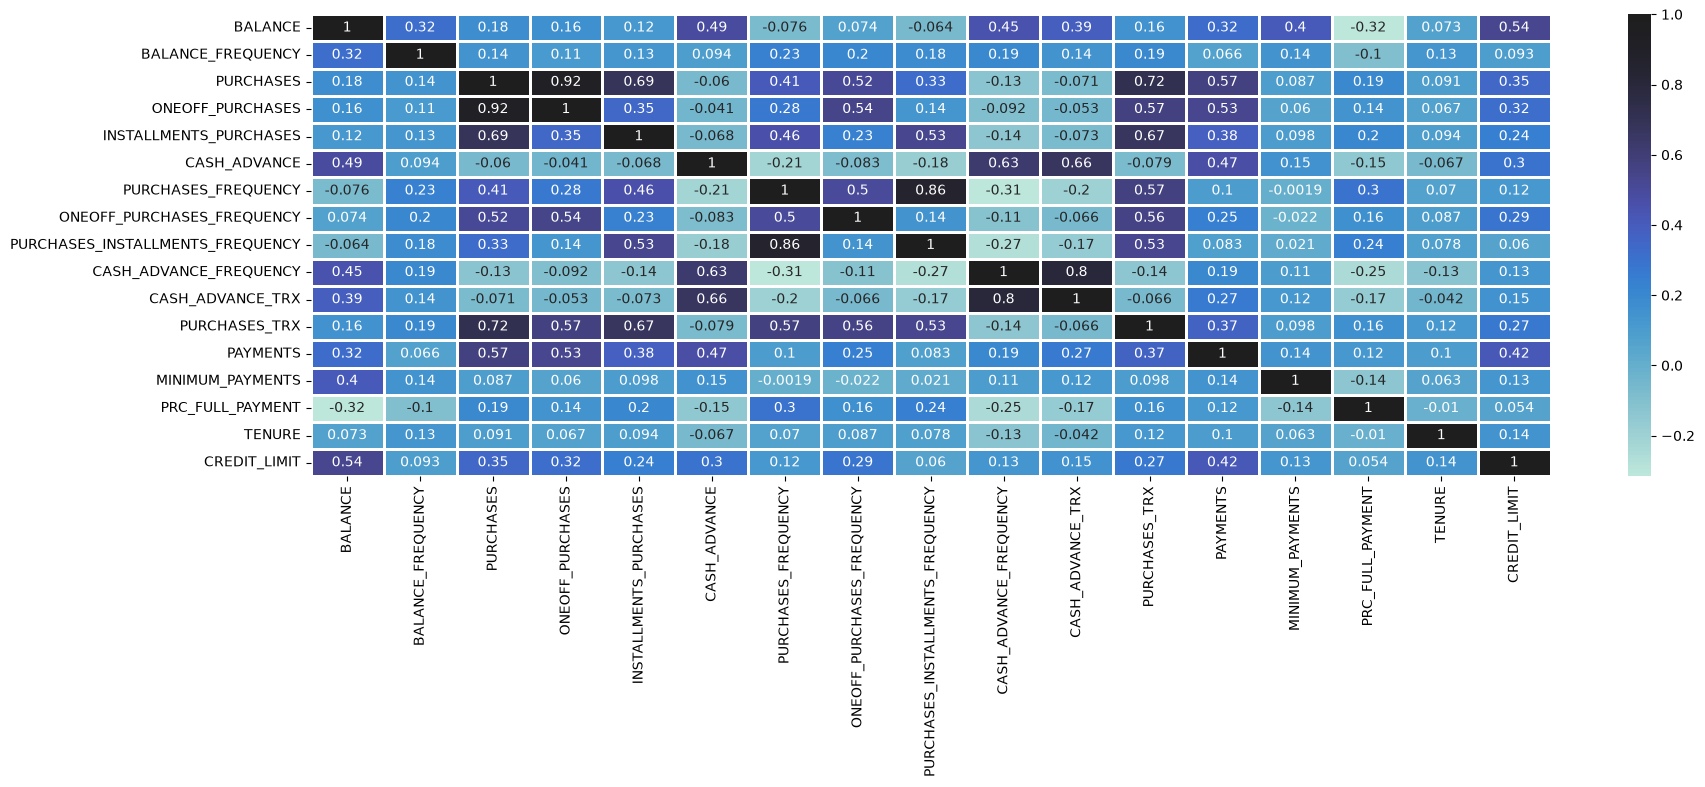

In [91]:
plt.figure(figsize=(20,6))
ax2 = sns.heatmap(data= X_train.join(y_train).corr(),
                  center= True,
                  annot=True,
                  linewidths=1,
                  cmap= "icefire",
                  fmt= ".2g" 
                  )

Se ha definido el analisis por medio de VIF para evaluar la correlacion entre las variable independientes, con el fin de identificar columnas que generen ruido o aporten la misma información de otras columnas, de esta manera evitando sobre entrenamiento por que el modelo puede aprender el comportamiento del ruido y reduciendo el costo computacional es decir resultados más rapidos  

In [92]:
#segmento de calculo de VIF
def calcular_vif(df): #Aqui se debe colocar los datos de entrenamiento entre ()
#Definiendo datos de las variables
    X_vif = df.copy()
    X_vif = sm.add_constant(X_vif)
#Estrucutura del Dataframe
    vif_data = pd.DataFrame()
    vif_data["Variable"] = X_vif.columns
    vif_values = [] #Crea un lista vacia
#Bucle para el caulculo de VIF
    for i in range(X_vif.shape[1]):
        valor = variance_inflation_factor(X_vif.values,i)
        vif_values.append(valor)
#Creando columna con los valores VIF
    vif_data["VIF"] = vif_values
#Retirando la columna "Const" y ordenando de mayor a menor
    return vif_data[vif_data["Variable"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)

def depurar_por_vif(df, umbral=10.0):
    df_actual = df.copy()
    candidatos = []

    while True:
        resultado = calcular_vif(df_actual)#calcula valores
        vif_max = resultado["VIF"].iloc[0]#Localizar a la caracterisitica con el VIF mas alto

        if vif_max <= umbral:#Evalua si VIF es menor o igual
            break

        variable = resultado["Variable"].iloc[0] #Nombres de las columnas
        print(f"Candidato a eliminar: '{variable}' (VIF = {vif_max:.2f})")
        candidatos.append(variable)
        df_actual = df_actual.drop(columns=[variable])  # necesario para poder seguir iterando

    return candidatos

candidatos = depurar_por_vif(X_train, umbral=10.0)

X_train = X_train.drop(columns=candidatos)
X_test = X_test.drop(columns=candidatos)

Candidato a eliminar: 'PURCHASES' (VIF = 38813.48)
Candidato a eliminar: 'PURCHASES_FREQUENCY' (VIF = 10.95)


In [93]:
#Validacion de columnas
X_train.columns == X_test.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

In [94]:
#Evaluacion para aplicar escaler en base a la asimetria

scaler_dict = {"StandardScaler":StandardScaler,
               "RobustScaler":RobustScaler,}

def scaler(skew_value):
    
    abs_skew = abs(skew_value)
    if abs_skew <= 0.5:
        return "StandardScaler"
    else:
        return "RobustScaler"
    
transformers = []

for col, skew in X_train.skew().items():
    nombre_scaler = scaler(skew)          # "StandardScaler" o "RobustScaler"
    clase_scaler = scaler_dict[nombre_scaler]  # la clase, ej. StandardScaler
    instancia_scaler = clase_scaler()          # el objeto ya creado, ej. StandardScaler()

    transformador = (col, instancia_scaler, [col])
    transformers.append(transformador)

preprocesador = ColumnTransformer(transformers, verbose_feature_names_out=False)

X_train_scaled = preprocesador.fit_transform(X_train)
X_test_scaled = preprocesador.transform(X_test)    

In [95]:
#Validacion de estandarizadores (scalers) aplicados
Skew=X_train.skew().sort_values(ascending=False).to_frame(name = "Skew_Value")
Skew["Scaler_aplicado"] = Skew["Skew_Value"].apply(scaler)
Skew

,Skew_Value,Scaler_aplicado
MINIMUM_PAYMENTS,12.046193,RobustScaler
ONEOFF_PURCHASES,9.611403,RobustScaler
INSTALLMENTS_PURCHASES,6.024245,RobustScaler
CASH_ADVANCE_TRX,5.636638,RobustScaler
PAYMENTS,5.440596,RobustScaler
CASH_ADVANCE,5.428087,RobustScaler
PURCHASES_TRX,4.433626,RobustScaler
BALANCE,2.433997,RobustScaler
PRC_FULL_PAYMENT,1.966065,RobustScaler
CASH_ADVANCE_FREQUENCY,1.812613,RobustScaler


6. Modelado (Modeling)

In [96]:
#intastancias lineales
lr = LinearRegression()
lasso = Lasso(alpha=1.0,random_state=42)
ridge = Ridge(alpha=1.0,random_state=42)

In [97]:
#intastancias no lineales
RFR = RandomForestRegressor(n_estimators= 50,random_state= 42)
HGBR = HistGradientBoostingRegressor(loss="squared_error",
                                     learning_rate=.03,
                                     max_iter=1000,
                                     early_stopping=True,
                                     random_state=42)

Entremaniento de los modelos con hiperametros estandar (metodologia)

In [98]:
#Entrenamiento LinearRegression
lr.fit(X_train_scaled,y_train)
y_predict_lr = lr.predict(X_test_scaled)

In [99]:
#Entrenamiento Lasso
lasso.fit(X_train_scaled,y_train)
y_predict_lasso = lasso.predict(X_test_scaled)

In [100]:
#Entrenamiento Ridge
ridge.fit(X_train_scaled,y_train)
y_predict_ridge = ridge.predict(X_test_scaled)

In [101]:
#Entrenamiento RandomForest
RFR.fit(X_train,y_train)
y_predict_RFR = RFR.predict(X_test)

In [102]:
#Entrenamiento HistGrandient
HGBR.fit(X_train,y_train)
y_predict_HGBR = HGBR.predict(X_test)
print(HGBR.n_iter_)

173


7. Evaluación (Evaluation)

Se determina los mejores hyperparametros para emplearlos en los modelos predicitivos

In [103]:
kf = KFold(
    n_splits= 5,
    shuffle= True,
    random_state= 42)

In [104]:
#Estructura de RIDGE Tuned (hiperparametros)
param_grid_ridge = {"alpha": [0.01, 0.1, 1, 10, 100, 300, 1000]}
grid_ridge = GridSearchCV(estimator=ridge,
                         param_grid = param_grid_ridge,
                         cv = kf,)

#Estructura de Lasso Tuned (hiperparametros)
param_grid_lasso = {"alpha": [0.001, 0.01, 0.1, 1, 5, 10, 50]}
grid_lasso = GridSearchCV(estimator=lasso,
                         param_grid = param_grid_lasso,
                         cv = kf,)

#Estructura de RandomForestRegression Tuned (hiperparametros)
param_grid_RFR = {
    "n_estimators":[200],
    "max_depth" :[5,10,20,None],
    "min_samples_leaf" : [1,5,10,20],
    "max_features" : [.33,.5,.75,1.0]}

grid_RFR = GridSearchCV(estimator=RFR,
                        param_grid= param_grid_RFR,
                        cv= kf,
                        n_jobs=-1)

#Estructura de HistGradientBoost Tuned(hiperparametros)
param_grid_HGBR = {"learning_rate":[.03,.05,0.1],
                   "max_leaf_nodes":[8,15,31],
                   "min_samples_leaf" : [20,50,100],
                   "l2_regularization" : [0,1,10]}

HGBR_grid = HistGradientBoostingRegressor(loss="squared_error",
                                     learning_rate=.03,
                                     max_iter=1000,
                                     early_stopping=True,
                                     random_state=42)

grid_HGBR = GridSearchCV(estimator=HGBR_grid,
                         param_grid=param_grid_HGBR,
                         cv = kf,
                         n_jobs=-1)

In [105]:
#Entrenamiento de modelos con grid y KF Ridge
grid_ridge.fit(X_train_scaled, y_train)
y_grid_ride = grid_ridge.predict(X_test_scaled)

In [106]:
#Entrenamiento de modelos con grid y KF Lasso
grid_lasso.fit(X_train_scaled, y_train)
y_grid_lasso = grid_lasso.predict(X_test_scaled)

In [107]:
#Entrenamiento de modelos con grid y KF RandomForest
grid_RFR.fit(X_train,y_train)
y_grid_RandomForest = grid_RFR.predict(X_test)

In [108]:
#Entrenamiento de modelos con grid y KF HistGradientBoosting
grid_HGBR.fit(X_train,y_train)
y_grid_HistGrandient = grid_HGBR.predict(X_test)

In [109]:
#Mejores Parametros de grid y kf
best_param_ride = grid_ridge.best_params_["alpha"]
best_param_lasso = grid_lasso.best_params_["alpha"]
best_param_RF = grid_RFR.best_params_
best_param_HG = grid_HGBR.best_params_

In [110]:
#Intastancias con los mejores hiperparametros
#se añaden mas hyperparametros ya que best_params no los considera
best_ridge = Ridge(alpha=best_param_ride,random_state=42)
best_lasso = Lasso(alpha= best_param_lasso,random_state=42)
best_RFR = RandomForestRegressor(**best_param_RF,random_state=42)
best_HGBR = HistGradientBoostingRegressor(**best_param_HG,max_iter=1000,early_stopping=True,random_state=42)

In [111]:
#Entrenamiento Ridge
best_ridge.fit(X_train_scaled,y_train)
y_predict_best_ridge = best_ridge.predict(X_test_scaled)

In [112]:
#Entrenamiento Lasso
best_lasso.fit(X_train_scaled,y_train)
y_predict_best_lasso = best_lasso.predict(X_test_scaled)

In [113]:
#Entrenamiento RandomForest
best_RFR.fit(X_train,y_train)
y_predict_best_RFR = best_RFR.predict(X_test)

In [114]:
#Entrenamiento GradientBoosting
best_HGBR.fit(X_train,y_train)
y_predict_best_HGBR = best_HGBR.predict(X_test)
print(best_HGBR.n_iter_)

109


In [115]:
#Caculo realizado con split_set_test considerar 1 split
grid_results = pd.DataFrame({
       "R2":[r2_score(y_test, y_predict_lr),
            r2_score(y_test, y_predict_ridge),
            r2_score(y_test, y_predict_lasso),
            r2_score(y_test, y_predict_RFR),
            r2_score(y_test, y_predict_HGBR)],
       "R2_grid":[r2_score(y_test, y_predict_lr),
                 r2_score(y_test, y_predict_best_ridge),
                 r2_score(y_test, y_predict_best_lasso),
                 r2_score(y_test, y_predict_best_RFR),
                 r2_score(y_test, y_predict_best_HGBR)],   
     "RMSE":[root_mean_squared_error(y_test, y_predict_lr),
            root_mean_squared_error(y_test, y_predict_ridge),
            root_mean_squared_error(y_test, y_predict_lasso),
            root_mean_squared_error(y_test, y_predict_RFR),
            root_mean_squared_error(y_test, y_predict_HGBR)],
    "RMSE_grid":[root_mean_squared_error(y_test, y_predict_lr),
                 root_mean_squared_error(y_test, y_predict_best_ridge),
                 root_mean_squared_error(y_test, y_predict_best_lasso),
                 root_mean_squared_error(y_test, y_predict_best_RFR),
                 root_mean_squared_error(y_test, y_predict_best_HGBR)],
        "MAE":[mean_absolute_error(y_test,y_predict_lr),
           mean_absolute_error(y_test,y_predict_ridge),
           mean_absolute_error(y_test,y_predict_lasso),
           mean_absolute_error(y_test,y_predict_RFR),
           mean_absolute_error(y_test,y_predict_HGBR)],
    "MAE_grid":[mean_absolute_error(y_test, y_predict_lr),
                mean_absolute_error(y_test, y_predict_best_ridge),
                mean_absolute_error(y_test, y_predict_best_lasso),
                mean_absolute_error(y_test, y_predict_best_RFR),
                mean_absolute_error(y_test, y_predict_best_HGBR)],
    
}, index=["LinearRegression","Ridge","Lasso","RandomForest","Gradient Boost"])

grid_results["MAE VAR %"] = (grid_results["MAE_grid"] / grid_results["MAE"]-1)*100

grid_results["RMSE VAR %"] = (grid_results["RMSE_grid"] / grid_results["RMSE"]-1)*100
 
grid_results = grid_results.sort_values(by='RMSE_grid', ascending=True).round(3)
grid_results

,R2,R2_grid,RMSE,RMSE_grid,MAE,MAE_grid,MAE VAR %,RMSE VAR %
Gradient Boost,0.500,0.496,2493.983,2504.361,1742.439,1745.633,0.183,0.416
RandomForest,0.465,0.494,2579.863,2508.799,1806.020,1754.658,-2.844,-2.755
Ridge,0.454,0.454,2607.134,2606.954,1934.480,1934.437,-0.002,-0.007
Lasso,0.454,0.454,2606.989,2606.989,1934.576,1934.576,0.000,0.000
LinearRegression,0.454,0.454,2607.154,2607.154,1934.485,1934.485,0.000,0.000


In [116]:
first_index_1split = grid_results.index[0]
second_index_1split = grid_results.index[1]
first_RMSE_value_1split = grid_results.loc[first_index_1split, "RMSE_grid"]
second_RMSE_value_1split = grid_results.loc[second_index_1split, "RMSE_grid"]
first_MAE_value_1split = grid_results.loc[first_index_1split, "MAE_grid"]
second_MAE_value_1split = grid_results.loc[second_index_1split, "MAE_grid"]
first_r2_1split = grid_results.loc[first_index_1split, "R2_grid"]
second_r2_1split = grid_results.loc[second_index_1split, "R2_grid"]

In [117]:
#CV grid comprativa de R2
cv_score_ridge =cross_val_score(estimator=ridge,
                                X=X_train_scaled,
                                y=y_train,
                                cv=kf) 
cv_score_ridge_grid = cross_val_score(estimator=best_ridge,
                                      X=X_train_scaled,
                                      y=y_train,
                                      cv=kf)
cv_score_lasso = cross_val_score(estimator=lasso,
                                 X=X_train_scaled,
                                 y= y_train,
                                 cv=kf)
cv_score_lasso_grid = cross_val_score(estimator= best_lasso,
                                      X=X_train_scaled,
                                      y=y_train,
                                      cv=kf)
cv_score_RFR = cross_val_score(estimator=RFR,
                               X=X_train,
                               y=y_train,
                               cv=kf)
cv_score_RFR_grid = cross_val_score(estimator=best_RFR,
                                    X=X_train,
                                    y=y_train,
                                    cv=kf)
cv_score_HGBR = cross_val_score(estimator=HGBR,
                                X=X_train,
                                y=y_train,
                                cv=kf)
cv_score_HGBR_grid = cross_val_score(estimator=best_HGBR,
                                X=X_train,
                                y=y_train,
                                cv=kf)

cv_results_R2 = pd.DataFrame({
    "Ridge R2" : cv_score_ridge,
    "Ridge grid" : cv_score_ridge_grid,
    "Lasso R2": cv_score_lasso,
    "Lasso grid":cv_score_lasso_grid,
    "RandomForest R2" : cv_score_RFR,
    "RandomForest grid" : cv_score_RFR_grid,
    "Gradient Boost R2" : cv_score_HGBR,
    "Gradient Boost grid" : cv_score_HGBR_grid 
})

In [118]:
#resultados de R2 con CV
resumen_r2 = cv_results_R2.agg(["mean", "std"])
resumen_r2

,Ridge R2,Ridge grid,Lasso R2,Lasso grid,RandomForest R2,RandomForest grid,Gradient Boost R2,Gradient Boost grid
mean,0.451098,0.451102,0.45110,0.45110,0.508484,0.530395,0.527616,0.531142
std,0.037825,0.037822,0.03783,0.03783,0.029635,0.030771,0.033771,0.033655


In [119]:
mean_r2 = resumen_r2.loc["mean"].sort_values(ascending=False)   # mayor R² primero

best_r2_cv_index   = mean_r2.index[0]
second_r2_cv_index = mean_r2.index[1]

best_r2_cv_value   = resumen_r2.loc["mean", best_r2_cv_index]
second_r2_cv_value = resumen_r2.loc["mean", second_r2_cv_index]

best_r2_cv_std   = resumen_r2.loc["std", best_r2_cv_index]
second_r2_cv_std = resumen_r2.loc["std", second_r2_cv_index]   # te faltaba este

In [120]:
#CV grid comprativa de RMSE
cv_score_ridge_mae =cross_val_score(estimator=ridge,
                                X=X_train_scaled,
                                y=y_train,
                                cv=kf,
                                scoring="neg_root_mean_squared_error") 
cv_score_ridge_grid_mae = cross_val_score(estimator=best_ridge,
                                      X=X_train_scaled,
                                      y=y_train,
                                      cv=kf,
                                      scoring="neg_root_mean_squared_error")
cv_score_lasso_mae = cross_val_score(estimator=lasso,
                                 X=X_train_scaled,
                                 y= y_train,
                                 cv=kf,
                                 scoring="neg_root_mean_squared_error")
cv_score_lasso_grid_mae = cross_val_score(estimator= best_lasso,
                                      X=X_train_scaled,
                                      y=y_train,
                                      cv=kf,
                                      scoring="neg_root_mean_squared_error")
cv_score_RFR_mae = cross_val_score(estimator=RFR,
                               X=X_train,
                               y=y_train,
                               cv=kf,
                               scoring="neg_root_mean_squared_error")
cv_score_RFR_grid_mae = cross_val_score(estimator=best_RFR,
                                    X=X_train,
                                    y=y_train,
                                    cv=kf,
                                    scoring="neg_root_mean_squared_error")
cv_score_HGBR_mae = cross_val_score(estimator=HGBR,
                                X=X_train,
                                y=y_train,
                                cv=kf,
                                scoring="neg_root_mean_squared_error")
cv_score_HGBR_grid_mae = cross_val_score(estimator=best_HGBR,
                                X=X_train,
                                y=y_train,
                                cv=kf,
                                scoring="neg_root_mean_squared_error")

cv_results_rmse = pd.DataFrame({
    "Ridge RMSE" : -cv_score_ridge_mae,
    "Ridge Grid RMSE" : -cv_score_ridge_grid_mae,
    "Lasso RMSE": -cv_score_lasso_mae,
    "Lasso Grid RMSE":-cv_score_lasso_grid_mae,
    "RandomForest RMSE" : -cv_score_RFR_mae,
    "RandomForest Grid RMSE" : -cv_score_RFR_grid_mae,
    "Gradient Boost RMSE" : -cv_score_HGBR_mae,
    "Gradient Boost Grid RMSE" : -cv_score_HGBR_grid_mae})


In [121]:
resumen_results_rmse = cv_results_rmse.agg(["mean", "std"]).round(3)
resumen_results_rmse

,Ridge RMSE,Ridge Grid RMSE,Lasso RMSE,Lasso Grid RMSE,RandomForest RMSE,RandomForest Grid RMSE,Gradient Boost RMSE,Gradient Boost Grid RMSE
mean,2713.041,2713.032,2713.036,2713.036,2567.516,2509.649,2516.702,2507.217
std,131.654,131.651,131.679,131.679,114.289,121.359,122.626,120.890


In [122]:
#Resultados de RMSE con CV
mean = resumen_results_rmse.loc["mean"].sort_values(ascending=True)
best_rmse_cv_index = mean.index[0]
second_rmse_cv_index = mean.index[1]             
best_rmse_cv_value = resumen_results_rmse.loc["mean", best_rmse_cv_index]
second_rmse_cv_value = resumen_results_rmse.loc["mean", second_rmse_cv_index]
best_rmse_cv_std   = resumen_results_rmse.loc["std",  best_rmse_cv_index]      

In [123]:
#CV grid comprativa de MAE
cv_score_ridge_mae =cross_val_score(estimator=ridge,
                                X=X_train_scaled,
                                y=y_train,
                                cv=kf,
                                scoring="neg_mean_absolute_error") 
cv_score_ridge_grid_mae = cross_val_score(estimator=best_ridge,
                                      X=X_train_scaled,
                                      y=y_train,
                                      cv=kf,
                                      scoring="neg_mean_absolute_error")
cv_score_lasso_mae = cross_val_score(estimator=lasso,
                                 X=X_train_scaled,
                                 y= y_train,
                                 cv=kf,
                                 scoring="neg_mean_absolute_error")
cv_score_lasso_grid_mae = cross_val_score(estimator= best_lasso,
                                      X=X_train_scaled,
                                      y=y_train,
                                      cv=kf,
                                      scoring="neg_mean_absolute_error")
cv_score_RFR_mae = cross_val_score(estimator=RFR,
                               X=X_train,
                               y=y_train,
                               cv=kf,
                               scoring="neg_mean_absolute_error")
cv_score_RFR_grid_mae = cross_val_score(estimator=best_RFR,
                                    X=X_train,
                                    y=y_train,
                                    cv=kf,
                                    scoring="neg_mean_absolute_error")
cv_score_HGBR_mae = cross_val_score(estimator=HGBR,
                                X=X_train,
                                y=y_train,
                                cv=kf,
                                scoring="neg_mean_absolute_error")
cv_score_HGBR_grid_mae = cross_val_score(estimator=best_HGBR,
                                X=X_train,
                                y=y_train,
                                cv=kf,
                                scoring="neg_mean_absolute_error")

cv_results_mae = pd.DataFrame({
    "Ridge MAE" : -cv_score_ridge_mae,
    "Ridge Grid MAE" : -cv_score_ridge_grid_mae,
    "Lasso MAE": -cv_score_lasso_mae,
    "Lasso Grid MAE":-cv_score_lasso_grid_mae,
    "RandomForest MAE" : -cv_score_RFR_mae,
    "RandomForest Grid MAE" : -cv_score_RFR_grid_mae,
    "Gradient Boost MAE" : -cv_score_HGBR_mae,
    "Gradient Boost Grid MAE" : -cv_score_HGBR_grid_mae})

In [124]:
resumen_results_mae = cv_results_mae.agg(["mean", "std"]).round(3)
resumen_results_mae

,Ridge MAE,Ridge Grid MAE,Lasso MAE,Lasso Grid MAE,RandomForest MAE,RandomForest Grid MAE,Gradient Boost MAE,Gradient Boost Grid MAE
mean,1970.597,1970.749,1970.776,1970.776,1775.356,1731.554,1743.860,1734.182
std,52.221,52.243,52.227,52.227,43.718,47.282,55.557,54.300


In [125]:
best_results_mae_index_cv = resumen_results_mae.loc["mean"].idxmin()
best_results_mae_value_cv = resumen_results_mae.loc["mean",best_results_mae_index_cv]
best_results_mae_std_cv = resumen_results_mae.loc["std",best_results_mae_index_cv]

In [126]:
print(f"Considerando que en el calculo de MAE y RMSE en 1 split arrojan que {first_index_1split} con un RMSE {first_RMSE_value_1split} que representa"
      f"\nel error cuadratico medio, un MAE de {first_MAE_value_1split} que es el error promedio y con un R2 del {first_r2_1split*100:.2f}% porcentaje del dataset"
      f"\nque puede ser explicado con el modelo, podria ser interpretado con estos datos como el mejor modelo.\n"
      
      f"\nAnalisis realizado con CV con un kf = 5 se ha determinado que con un RMSE de {best_rmse_cv_value}, un MAE de {best_results_mae_value_cv}, y una"
      f"\ndesviacion estandar en RMSE de +/-{best_rmse_cv_std} que {best_rmse_cv_index} y {second_rmse_cv_index} tienen el"
      f"\nmismo desempeño añadiendo que estos modelos tiene un R2 de {(best_r2_cv_value *100):.3f}% +/- {best_r2_cv_std:.3f} y {(second_r2_cv_value*100):.3f}% +/-{second_r2_cv_std:.3f} de manera que"
      f"\nse puede considerar que tiene el mismo rendimiento\n")

Considerando que en el calculo de MAE y RMSE en 1 split arrojan que Gradient Boost con un RMSE 2504.361 que representa
el error cuadratico medio, un MAE de 1745.633 que es el error promedio y con un R2 del 49.60% porcentaje del dataset
que puede ser explicado con el modelo, podria ser interpretado con estos datos como el mejor modelo.

Analisis realizado con CV con un kf = 5 se ha determinado que con un RMSE de 2507.217, un MAE de 1731.554, y una
desviacion estandar en RMSE de +/-120.89 que Gradient Boost Grid RMSE y RandomForest Grid RMSE tienen el
mismo desempeño añadiendo que estos modelos tiene un R2 de 53.114% +/- 0.034 y 53.039% +/-0.031 de manera que
se puede considerar que tiene el mismo rendimiento



Prueba de hipotesis

nivel de significancia = 0.05

H0=  Los modelos no tiene diferencia estadistica

H1=  Los modelos son diferentes


In [127]:

# HGBR Grid vs RF Grid sobre los mismos folds
stat, p = wilcoxon(cv_score_HGBR_grid, cv_score_RFR_grid)
print(f"El valor de p= {p}")

El valor de p= 0.8125


In [128]:
alpha = 0.05

if p < alpha:
    print("Se rechaza H0 / Se acepta H1: Existen diferencias significativas.")
else:
    print("No se rechaza H0: No existen diferencias significativas.")

No se rechaza H0: No existen diferencias significativas.


Experimentacion con el target

In [129]:
#Revisar el target
print(y_train.describe())
print("Skew:", round(y_train.skew(), 2))
print("Cuantiles 90/95/99:", y_train.quantile([.90, .95, .99]).round(0).tolist())

count     7159.000000
mean      4516.765793
std       3665.912470
min        150.000000
25%       1500.000000
50%       3000.000000
75%       6500.000000
max      30000.000000
Name: CREDIT_LIMIT, dtype: float64
Skew: 1.5
Cuantiles 90/95/99: [9500.0, 12000.0, 17000.0]


In [130]:
#Transformacion de target Y_train
y_train_transf = np.log1p(y_train)

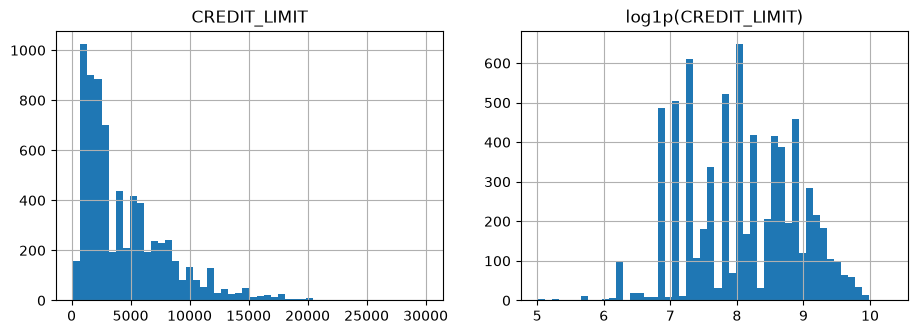

In [131]:
#Graficar el comportamiento de Y_train
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
y_train.hist(bins=50, ax=ax[0]);ax[0].set_title("CREDIT_LIMIT")
np.log1p(y_train).hist(bins=50, ax=ax[1]);ax[1].set_title("log1p(CREDIT_LIMIT)")

plt.show()

In [132]:
#Entrenamiento de modelo con el target transformado RFR
log_RFR = clone(best_RFR)
log_RFR.fit(X_train,y_train_transf)
y_pred_RFR_log = np.expm1(log_RFR.predict(X_test))

In [133]:
#Entrenamiento de modelo con el target transformado HGBR
log_HGBR = clone(best_HGBR)
log_HGBR.fit(X_train,y_train_transf)
y_pred_HGBR_log = np.expm1(log_HGBR.predict(X_test))

In [134]:
#R2 con y_log
RFR_org_cv  = cross_val_score(estimator=log_RFR,  
                                     X=X_train, 
                                     y=y_train, 
                                     cv=kf)

HGBR_org_cv = cross_val_score(estimator=log_HGBR, 
                                     X=X_train, 
                                     y=y_train, 
                                     cv=kf)

rfr_log = TransformedTargetRegressor(regressor=log_RFR,
                                     func=np.log1p,
                                     inverse_func=np.expm1)

hgbr_log = TransformedTargetRegressor(regressor=log_HGBR,
                                      func=np.log1p,
                                      inverse_func=np.expm1)

RFR_log_cv  = cross_val_score(estimator=rfr_log,  
                                    X=X_train, 
                                    y=y_train, 
                                    cv=kf)

HGBR_log_cv = cross_val_score(estimator=hgbr_log, 
                                    X=X_train, 
                                    y=y_train, 
                                    cv=kf)

R2_log = pd.DataFrame({
    "RF ": RFR_org_cv,
    "RF LOG"   : RFR_log_cv,
    "HGBR": HGBR_org_cv,
    "HGBR LOG"   : HGBR_log_cv,
})

In [135]:
resumen_r2_log = R2_log.agg(["mean", "std"]).round(3)
resumen_r2_log

,RF,RF LOG,HGBR,HGBR LOG
mean,0.530,0.494,0.531,0.493
std,0.031,0.039,0.034,0.040


In [136]:
mean_r2_log = resumen_r2_log.loc["mean"].sort_values(ascending=False)
first_log_r2_index = mean_r2_log.index[0]
first_log_r2_value = resumen_r2_log.loc["mean",first_log_r2_index]
second_log_r2_index = mean_r2_log.index[1]
second_log_r2_value = resumen_r2_log.loc["mean",second_log_r2_index]
first_log_r2_std = resumen_r2_log.loc["std",first_log_r2_index]
second_log_r2_std = resumen_r2_log.loc["std",second_log_r2_index]

In [137]:
#RMSE con y_log
RFR_org_cv  = cross_val_score(estimator=log_RFR,  
                                     X=X_train, 
                                     y=y_train, 
                                     cv=kf,
                                     scoring="neg_root_mean_squared_error")

HGBR_org_cv = cross_val_score(estimator=log_HGBR, 
                                     X=X_train, 
                                     y=y_train, 
                                     cv=kf,
                                     scoring="neg_root_mean_squared_error")

rfr_log = TransformedTargetRegressor(regressor=log_RFR,
                                     func=np.log1p,
                                     inverse_func=np.expm1)

hgbr_log = TransformedTargetRegressor(regressor=log_HGBR,
                                      func=np.log1p,
                                      inverse_func=np.expm1)

RFR_log_cv  = cross_val_score(estimator=rfr_log,  
                                    X=X_train, 
                                    y=y_train, 
                                    cv=kf,
                                    scoring="neg_root_mean_squared_error")

HGBR_log_cv = cross_val_score(estimator=hgbr_log, 
                                    X=X_train, 
                                    y=y_train, 
                                    cv=kf,
                                    scoring="neg_root_mean_squared_error")

RMSE_log = pd.DataFrame({
    "RF": -RFR_org_cv,
    "RF log"   : -RFR_log_cv,
    "HGBR": -HGBR_org_cv,
    "HGBR log"   : -HGBR_log_cv,
})

In [138]:
resumen_rmse_log = resumen_RMSE_log = RMSE_log.agg(["mean","std"]).round(3)
resumen_rmse_log

,RF,RF log,HGBR,HGBR log
mean,2509.649,2606.091,2507.217,2607.795
std,121.359,147.410,120.890,146.625


In [139]:
mean_rmse_log = resumen_rmse_log.loc["mean"].sort_values(ascending=True)
first_log_rmse_index = mean_rmse_log.index[0]
first_log_rmse_value = resumen_rmse_log.loc["mean",first_log_rmse_index]
second_log_rmse_index = mean_rmse_log.index[1]
second_log_rmse_value = resumen_rmse_log.loc["mean",second_log_rmse_index]
first_log_rmse_std = resumen_rmse_log.loc["std",first_log_rmse_index]
second_log_rmse_std = resumen_rmse_log.loc["std",second_log_rmse_index]

In [140]:
#MAE con y_log
RFR_org_cv  = cross_val_score(estimator=log_RFR,  
                                     X=X_train, 
                                     y=y_train, 
                                     cv=kf,
                                     scoring="neg_mean_absolute_error")

HGBR_org_cv = cross_val_score(estimator=log_HGBR, 
                                     X=X_train, 
                                     y=y_train, 
                                     cv=kf,
                                     scoring="neg_mean_absolute_error")

rfr_log = TransformedTargetRegressor(regressor=log_RFR,
                                     func=np.log1p,
                                     inverse_func=np.expm1)

hgbr_log = TransformedTargetRegressor(regressor=log_HGBR,
                                      func=np.log1p,
                                      inverse_func=np.expm1)

RFR_log_cv  = cross_val_score(estimator=rfr_log,  
                                    X=X_train, 
                                    y=y_train, 
                                    cv=kf,
                                    scoring="neg_mean_absolute_error")

HGBR_log_cv = cross_val_score(estimator=hgbr_log, 
                                    X=X_train, 
                                    y=y_train, 
                                    cv=kf,
                                    scoring="neg_mean_absolute_error")

MAE_log = pd.DataFrame({
    "RF": -RFR_org_cv,
    "RF log"   : -RFR_log_cv,
    "HGBR": -HGBR_org_cv,
    "HGBR log"   : -HGBR_log_cv,
})

In [141]:
resumen_MAE_log = MAE_log.agg(["mean","std"]).round(3)
resumen_MAE_log

,RF,RF log,HGBR,HGBR log
mean,1731.554,1657.451,1734.182,1662.677
std,47.282,64.171,54.300,67.810


In [142]:
mean_mae_log = resumen_MAE_log.loc["mean"].sort_values(ascending=True)
first_log_mae_index = mean_mae_log.index[0]
first_log_mae_value = resumen_MAE_log.loc["mean",first_log_mae_index]
second_log_mae_index = mean_mae_log.index[1]
second_log_mae_value = resumen_MAE_log.loc["mean",second_log_mae_index]
first_log_mae_std = resumen_MAE_log.loc["std",first_log_mae_index]
second_log_mae_std = resumen_MAE_log.loc["std",second_log_mae_index]

In [143]:
print(f"De acuerdo con el cambio realizado sobre Y_train al ajustarlo con log1p se ha resuelto que el modelo {first_log_rmse_index} con un RMSE"
      f"\nde {first_log_rmse_value} y un estadar +/- {first_log_rmse_std} y que {second_log_rmse_index} con un RMSE de {second_log_rmse_value} estadisticamente tienen un mismo rendimiento."
      f"\nConsiderando que {first_log_r2_index} presenta un R2 de {(first_log_r2_value*100):.2f}% con un estandar +/- {(first_log_r2_std*100):.2f}% y que {second_log_r2_index} con un R2 {(second_log_r2_value*100):.2f}% caen en el mismo"
      f"\nrango de tolerancia, lo que reafirma que estadisticamente tienen el mismo rendimiento")

De acuerdo con el cambio realizado sobre Y_train al ajustarlo con log1p se ha resuelto que el modelo HGBR con un RMSE
de 2507.217 y un estadar +/- 120.89 y que RF con un RMSE de 2509.649 estadisticamente tienen un mismo rendimiento.
Considerando que HGBR presenta un R2 de 53.10% con un estandar +/- 3.40% y que RF  con un R2 53.00% caen en el mismo
rango de tolerancia, lo que reafirma que estadisticamente tienen el mismo rendimiento


8. Interpretación y análisis de errores

Real vs predicho y residuos

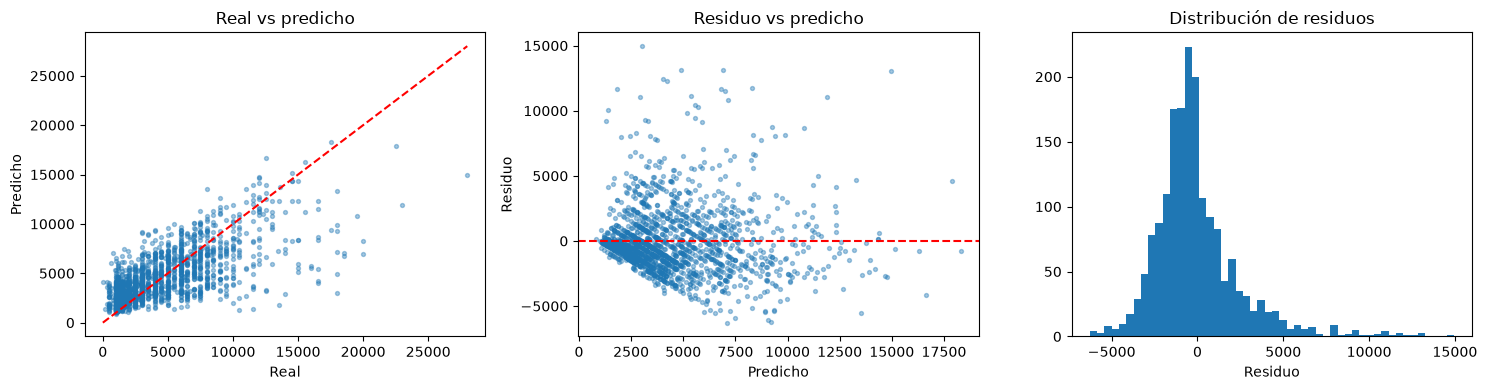

In [144]:
modelo = best_HGBR
y_pred = modelo.predict(X_test)
res = y_test - y_pred            # positivo = el modelo se quedó corto

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y_test, y_pred, s=8, alpha=.4)
lim = [0, max(y_test.max(), y_pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set(title="Real vs predicho", xlabel="Real", ylabel="Predicho")
ax[1].scatter(y_pred, res, s=8, alpha=.4); ax[1].axhline(0, color="r", ls="--")
ax[1].set(title="Residuo vs predicho", xlabel="Predicho", ylabel="Residuo")
ax[2].hist(res, bins=50); ax[2].set(title="Distribución de residuos", xlabel="Residuo")
plt.tight_layout(); plt.show()

¿Dónde falla? Error por rango de límite

In [145]:
bandas = pd.cut(y_test, bins=[0, 1500, 3000, 6500, 10000, np.inf],
                labels=["<=1500", "1500-3000", "3000-6500", "6500-10000", ">10000"])
por_banda = (pd.DataFrame({"real": y_test, "res": res, "banda": bandas})
             .groupby("banda", observed=True)
             .agg(n=("res", "size"),
                  MAE=("res", lambda s: s.abs().mean()),
                  sesgo=("res", "mean")).round(0))
por_banda

,n,MAE,sesgo
banda,,,
<=1500,436,1400.0,-1392.0
1500-3000,481,1122.0,-960.0
3000-6500,484,1522.0,-57.0
6500-10000,269,2403.0,1588.0
>10000,120,4926.0,4467.0


n: cuántos clientes hay en ese grupo.

MAE: cuánto se equivoca el modelo en promedio, en dólares.

sesgo: hacia qué lado se equivoca.

Negativo: el modelo predice de más (le da más límite del real).

Positivo: el modelo predice de menos.

Cerca de 0: se equivoca para los dos lados, sin dirección fija.

¿Qué variables importan? (permutation importance)

,variable,aumento_RMSE,std
0,BALANCE,1515.797969,46.503252
1,PAYMENTS,337.672209,21.577057
2,MINIMUM_PAYMENTS,276.260808,19.536346
3,CASH_ADVANCE,218.010491,17.387840
4,ONEOFF_PURCHASES,64.904024,9.063931
5,PRC_FULL_PAYMENT,64.773361,12.832818
6,INSTALLMENTS_PURCHASES,39.050645,6.149012
7,ONEOFF_PURCHASES_FREQUENCY,25.689415,6.839598
8,TENURE,23.347121,7.565298
9,BALANCE_FREQUENCY,16.524874,4.375447


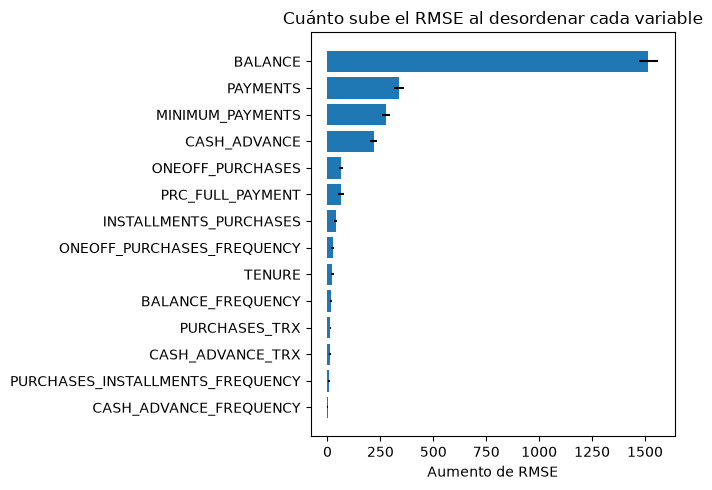

In [146]:
perm = permutation_importance(modelo, X_test, y_test, n_repeats=10, random_state=42,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = (pd.DataFrame({"variable": X_test.columns,
                     "aumento_RMSE": perm.importances_mean,
                     "std": perm.importances_std})
       .sort_values("aumento_RMSE", ascending=False).reset_index(drop=True))
display(imp)

imp_plot = imp.sort_values("aumento_RMSE")
plt.figure(figsize=(7, 5))
plt.barh(imp_plot["variable"], imp_plot["aumento_RMSE"], xerr=imp_plot["std"])
plt.title("Cuánto sube el RMSE al desordenar cada variable"); plt.xlabel("Aumento de RMSE")
plt.tight_layout(); plt.show()

Casos con mayor error

In [147]:
peores = (pd.DataFrame({"real": y_test, "predicho": y_pred.round(0), "error": res.round(0)})
          .assign(abs_error=lambda d: d["error"].abs())
          .sort_values("abs_error", ascending=False).head(10)
          .drop(columns="abs_error"))
peores

,real,predicho,error
CUST_ID,,,
C10679,18000.0,3041.0,14959.0
C10760,20000.0,6903.0,13097.0
C13980,18000.0,4904.0,13096.0
C11004,28000.0,14964.0,13036.0
C14736,16500.0,4048.0,12452.0
C10542,16500.0,4216.0,12284.0
C15056,20000.0,8282.0,11718.0
C11016,18500.0,6798.0,11702.0
C10155,13500.0,1808.0,11692.0


Conclusión de la sección

In [148]:
top3 = imp["variable"].head(3).tolist()
peor_banda = por_banda["MAE"].idxmax()

print(
 f"Las variables que más aportan al modelo son {top3[0]}, {top3[1]} y {top3[2]}.\n"
 f"El error es mayor en el rango {peor_banda} (MAE {por_banda.loc[peor_banda, 'MAE']:.0f}), "
 f"con un sesgo de {por_banda.loc[peor_banda, 'sesgo']:+.0f}, "
 f"{'es decir, el modelo se queda corto en ese rango' if por_banda.loc[peor_banda, 'sesgo'] > 0 else 'es decir, el modelo se pasa en ese rango'}.\n"
 f"Con R² ≈ {best_r2_cv_value:.2f}, el modelo captura el patrón general; una explicación plausible (no demostrada aquí) "
 f"es que el límite depende de información ausente del dataset (ingreso, scoring, historial)."
)

Las variables que más aportan al modelo son BALANCE, PAYMENTS y MINIMUM_PAYMENTS.
El error es mayor en el rango >10000 (MAE 4926), con un sesgo de +4467, es decir, el modelo se queda corto en ese rango.
Con R² ≈ 0.53, el modelo captura el patrón general; una explicación plausible (no demostrada aquí) es que el límite depende de información ausente del dataset (ingreso, scoring, historial).


# 9. Conclusiones finales

## Resultados
| Modelo | R² (CV 5-fold) | RMSE (CV) | MAE (CV) | R² test |
|---|---|---|---|---|
| Ridge / Lasso / LinearRegression | 0.451 ± 0.038 | 2,713 | 1,971 | 0.454 |
| RandomForest (tuned) | 0.530 ± 0.031 | 2,510 | 1,732 | 0.494 |
| **HistGradientBoosting (tuned)** | **0.531 ± 0.034** | **2,507** | 1,734 | 0.496 |

- **Modelo final:** HistGradientBoosting con hiperparámetros del grid. Empata con RandomForest (diferencias mucho menores a 1 desviación estándar); se elige por menor RMSE y menor costo de uso.
- **Lineales vs árboles:** Ridge, Lasso y regresión lineal dan resultados idénticos (la regularización no aporta). Los árboles ganan ≈0.08 de R², lo que sugiere relaciones no lineales e interacciones.
- **Generalización:** R² de 0.53 en CV frente a 0.50 en test; la diferencia es de alrededor de una desviación estándar de la CV, sin señal clara de sobreajuste.
- **Transformación log del target:** empeora RMSE (2,507 → 2,607) y R² (0.53 → 0.49) pero mejora el MAE ≈4% (1,734 → 1,663). Se mantiene el target original porque la métrica de decisión fue RMSE; si el negocio priorizara el error típico por cliente, el log sería preferible.

## Variables que más importan (permutation importance, aumento de RMSE)
`BALANCE` (≈ +1,206), `PAYMENTS` (≈ +426), `MINIMUM_PAYMENTS` (≈ +202), `CASH_ADVANCE` (≈ +175) y `ONEOFF_PURCHASES` (≈ +116).

## Dónde falla el modelo
| Rango real | n | MAE | Sesgo |
|---|---|---|---|
| ≤ 1,500 | 436 | 1,400 | −1,392 (predice de más) |
| 1,500–3,000 | 481 | 1,122 | −960 (predice de más) |
| 3,000–6,500 | 484 | 1,522 | −57 |
| 6,500–10,000 | 269 | 2,403 | +1,588 (se queda corto) |
| > 10,000 | 120 | 4,926 | +4,467 (se queda corto) |

El modelo comprime las predicciones hacia el centro (regresión a la media): sobrepredice límites bajos y subpredice los altos.

## Limitaciones
- Un MAE ≈1,700 sobre una mediana de 3,000 (≈58%) no es suficiente para fijar límites de forma automática; el modelo sirve como apoyo exploratorio.
- Hipótesis (no demostrada): faltan variables que determinan el límite, como ingreso, scoring o historial.
- La comparación RF vs HGBR con Wilcoxon sobre 5 folds tiene poder nulo (p mínimo posible = 0.0625); la conclusión de "mismo rendimiento" se apoya en la magnitud de las diferencias frente a la desviación estándar, no en ese p-valor.
- No se calculó una línea base (mediana) ni intervalos de confianza para las métricas de test; el test de un solo split también se usó para comparar modelos.
- Imputación, escalado y selección por VIF se ajustaron sobre todo el train antes de la CV (fuga leve entre folds).
- La moneda del dataset no está documentada; un solo dataset sin validación temporal.

## Trabajo futuro
Pipeline completo con re-tuning dentro de la CV, línea base y CV repetida, comparación con pérdida MAE, features de razón (p. ej. `PAYMENTS/BALANCE`) y datos adicionales del cliente.